DiD: Neuenburg vs. Aargau (Einführung 2018)

Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.416        0.149 0.00521 0.475        -34.0


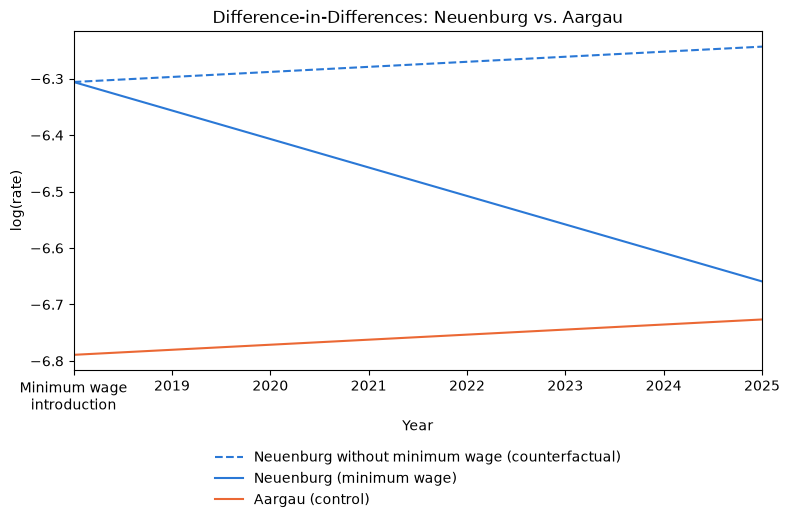

In [16]:
##Neuenburg - Aargau
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Neuenburg"
KONTROLL_KANTON    = "Aargau"
EINFUEHRUNG        = 2018          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())

DiD: Neuenburg vs. St. Gallen (Einführung 2018)

Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.647        0.155 0.00003 0.444        -47.6


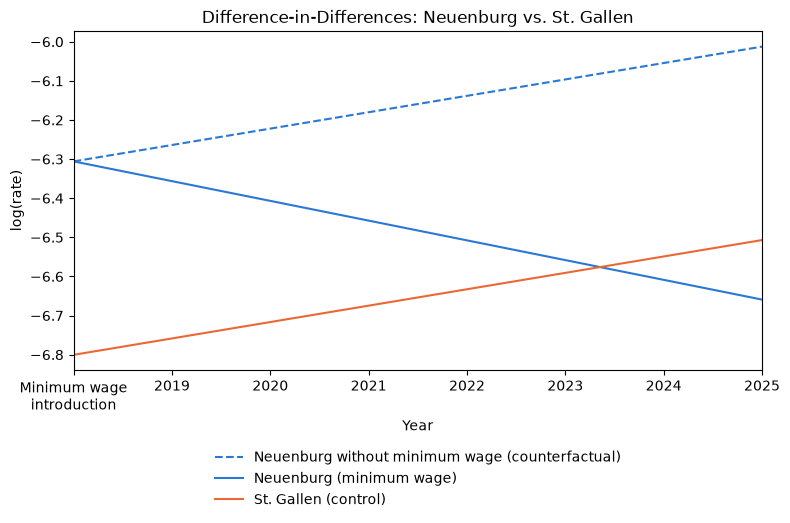

In [15]:
##Neuenburg - St GAllen

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Neuenburg"
KONTROLL_KANTON    = "St. Gallen"
EINFUEHRUNG        = 2018          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())

DiD: Genf vs. Luzern (Einführung 2021)

Modell  β3 (DiD)  Std.-Fehler  p-Wert   R²  Effekt in %
   DiD     -0.32        0.208 0.12418 0.89        -27.4


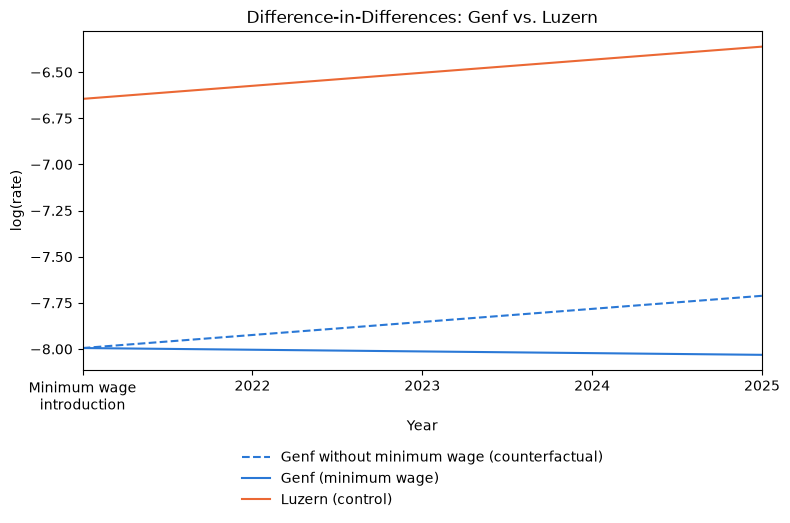

In [17]:
##Genf - Luzern

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTON    = "Luzern"
EINFUEHRUNG        = 2021          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())

DiD: Genf vs. Aargau (Einführung 2021)

Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.195        0.198 0.32552 0.873        -17.7


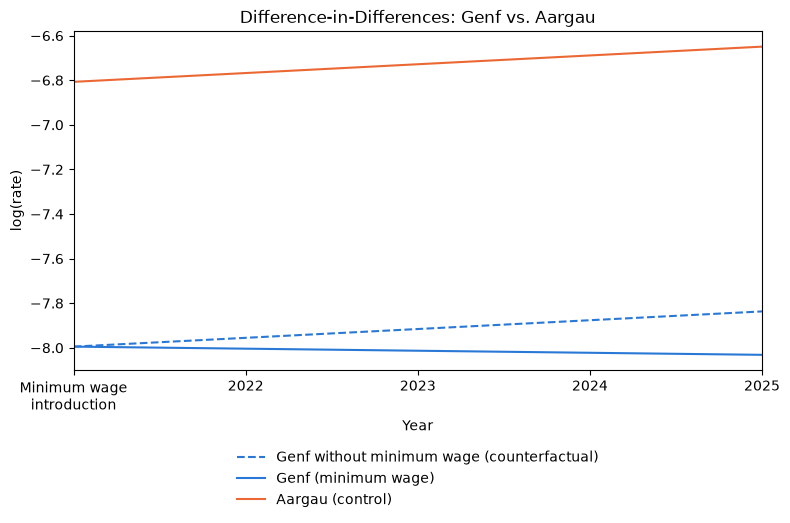

In [19]:
##Genf - Aargau

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTON    = "Aargau"
EINFUEHRUNG        = 2021          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())

DiD: Genf vs. Wallis (Einführung 2021)

Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD     0.645        0.262 0.01382 0.364         90.6


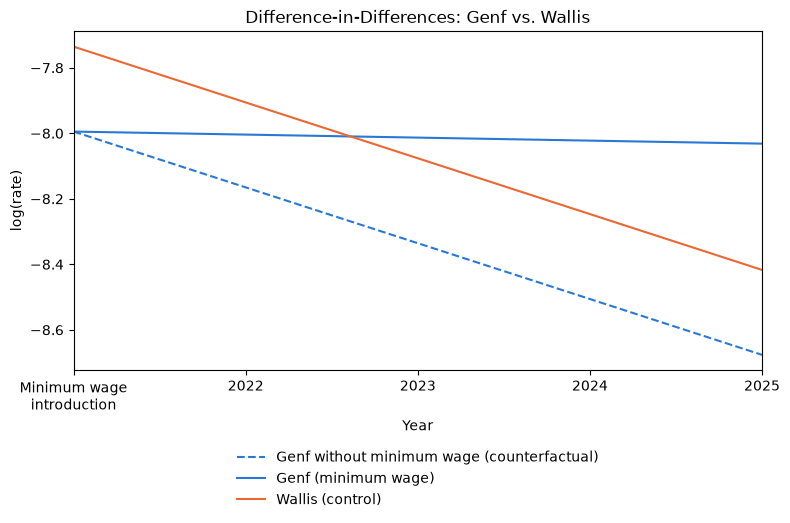

In [20]:
### Genf - Wallis

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTON    = "Wallis"
EINFUEHRUNG        = 2021          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())

DiD: Genf vs. St. Gallen (Einführung 2021)

Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.427        0.191 0.02514 0.892        -34.8


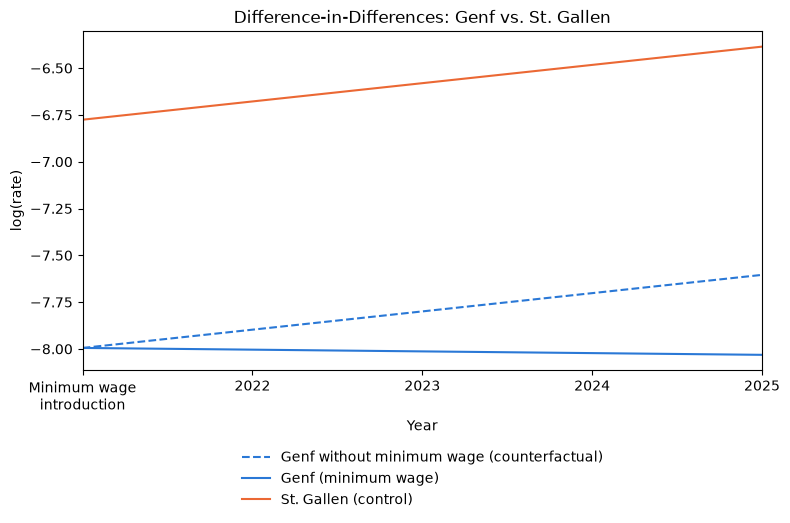

In [23]:
###Genf -ST GAllen

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTON    = "St. Gallen"
EINFUEHRUNG        = 2021          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())

DiD: Basel-Stadt vs. Luzern (Einführung 2023)

Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.706        0.148     0.0 0.793        -50.6


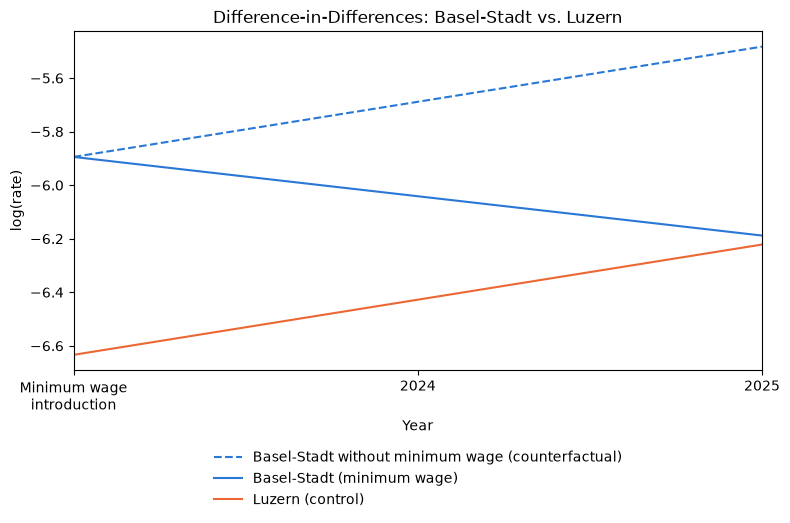

In [25]:
###Basel Stadt - Luzern

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Basel-Stadt"
KONTROLL_KANTON    = "Luzern"
EINFUEHRUNG        = 2023          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())

DiD: Basel-Stadt vs. Aargau (Einführung 2023)

Modell  β3 (DiD)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.314        0.157 0.04533 0.861        -27.0


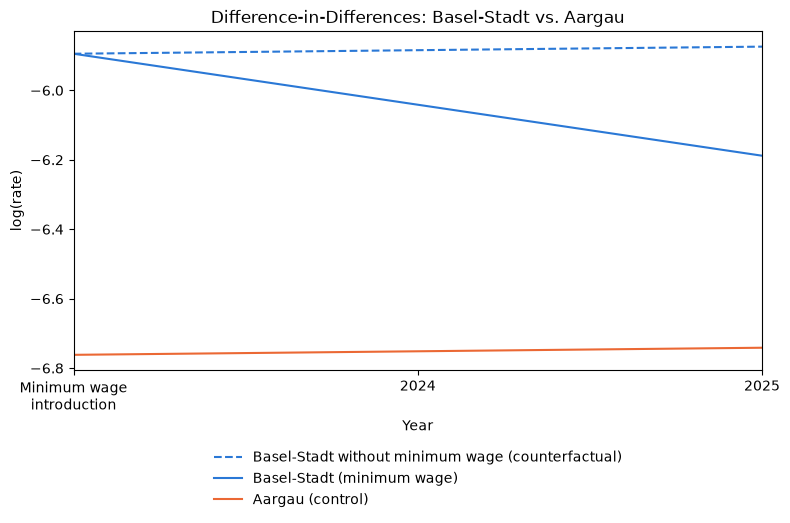

In [26]:
### Basel-Stadt - Aargau

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen: Paar und Einführungsjahr
# =============================================================
MINDESTLOHN_KANTON = "Basel-Stadt"
KONTROLL_KANTON    = "Aargau"
EINFUEHRUNG        = 2023          # erstes volles Jahr mit Mindestlohn

# =============================================================
# 2. Daten laden und vorbereiten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON, KONTROLL_KANTON])].copy()

# Outcome: log der Rate (Beschuldigte / Bevölkerung)
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])

# Variablen wie in den Notizen
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)   # 1 = Mindestlohn-Kanton
d["After"] = (d["Year"] >= EINFUEHRUNG).astype(int)            # 1 = nach Einführung

# =============================================================
# 3. Regressionen
# =============================================================
# Variante A: klassische DiD
#   Y = b0 + b1*Treat + b2*After + b3*Treat*After + u
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# Variante B: mit Kantons- und Jahres-Fixed-Effects
#   Treat -> C(Canton), After -> C(Year)
#mB = smf.ols("log_rate ~ Treat:After + C(Canton) + C(Year)", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"], #"B: Kantons- + Jahres-FE"],
    "β3 (DiD)": [mA.params["Treat:After"]],# mB.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],# mB.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],# mB.pvalues["Treat:After"]],
    "R²": [mA.rsquared],# mB.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (DiD)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON} (Einführung {EINFUEHRUNG})\n")
print(ergebnis.round({"β3 (DiD)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

import matplotlib.pyplot as plt

b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]

# x-Achse: vom Einführungsjahr bis zum letzten Jahr in den Daten
jahre = list(range(EINFUEHRUNG, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

treat      = [b0 + b1, b0 + b1 + b2 + b3]   # Mindestlohn-Kanton
kontrolle  = [b0,      b0 + b2]             # Kontrollkanton
kontrafakt = [b0 + b1, b0 + b1 + b2]        # Mindestlohn-Kanton ohne Mindestlohn

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"{KONTROLL_KANTON} (control)")

beschriftung = ["Minimum wage\nintroduction"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("log(rate)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {KONTROLL_KANTON}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

# Für die ganze Tabelle eines Modells:
# print(mA.summary())